# KOSPI200·KOSPI100 신규 편입 예측 전략

추세 파라미터 갱신 · **평가 기준일 2026년 11월 20일**. 인샘플 샤프로 고른 시총 추세보정 값은 코스피200 ¼·±0.2, 코스피100 1.0·한도 없음입니다. 심사마감 80·60·40·20거래일 전 4회 신호를 사용합니다. 각 전략의 고정 주문 예산은 100억 원, 통합 초기 원금은 200억 원입니다.

공표 명단에서 빠진 종목은 다음 거래일 종가부터, 편입된 종목은 패시브 리밸런싱일부터 거래대금 한도 내에서 청산합니다. 공표 결과가 미확인인 종목은 실패로 간주하지 않습니다. 2026년 하반기 원장은 당시 이용 가능 정보를 기준으로 **지금 재구성한 모의 원장**이며 실제 증권계좌 또는 당시 저장한 전진 주문 기록이 아닙니다.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
root=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'04_results').is_dir())
IDS=('KOSPI200','KOSPI100')
OUT=root/'04_results/kospi_pair_optimized_trend_20261124'
SRC=root/'04_results/common_index_engine_20261119'
perf=pd.read_csv(OUT/'standalone_splits.csv')
stand=pd.concat([
    pd.read_parquet(OUT/f'{idx}_{phase}_daily.parquet').query('index_id==@idx').assign(phase=phase)
    for idx in IDS for phase in ('IS','OOS')],ignore_index=True)
metrics=pd.read_csv(OUT/'metrics.csv')
daily=pd.read_parquet(OUT/'OOS_daily.parquet')
oos=daily.query("index_id=='COMBINED'").set_index('date')
def show(df):
    pct=['total_return','cagr','volatility','mdd','initial_fill_ratio','mean_exposure','precision','recall']
    display(df.style.format({k:'{:.2%}' for k in pct if k in df.columns} | {k:'{:.3f}' for k in df if 'sharpe' in k}))


## 1. 연구 가설과 ETF 추종자금

신규 편입주에 매수 수요가 생기고, 그 명단을 미리 예측하면 비용을 제하고도 수익이 남는다는 가설입니다. ETF 순자산에는 주가 상승과 설정·환매가 함께 반영됩니다. 2026년 11월 수치는 OOS 종료 후의 시장 규모입니다. 이 노트의 운용 대상은 KOSPI200과 KOSPI100입니다.


In [2]:
aum=pd.read_csv(root/'04_results/presentation_v4_20261118/etf_aum_yearly.csv')
display(aum[aum.index_id.isin(IDS)].pivot(index='year',columns='index_id',values='aum_krw').div(1e12).rename_axis('연도 · 조 원').round(3))


index_id,KOSPI100,KOSPI200
연도 · 조 원,,
2010,0.000,2.886
2011,0.475,4.516
2012,0.320,8.080
2013,0.176,10.899
2014,0.155,9.781
2015,0.099,9.511
2016,0.099,10.116
2017,0.073,14.923
2018,0.042,15.961


## 2. 선정 규정과 완만한 시가총액 추세 보정

KOSPI200은 당시 산업군별 심사 평균 시총·거래대금과 기존 구성종목 보호 규칙을 적용합니다. 현행 기준은 산업군별 누적 시총 85%와 거래대금 순위 상위 85%를 각각 봅니다. KOSPI100은 같은 심사에서 예상한 KOSPI200 안에서 평균 시총을 비교하고 기존 종목 120위·신규 80위 완충을 반영합니다. 2026년 12월의 KRICS 분류는 상반기까지의 백테스트에 소급하지 않습니다. 초기 규정·업종·모지수 이력 일부는 보관된 연구 입력으로 근사했습니다. [방법론 원문](../지수_방법론)

신호일까지 관측한 시총과 거래일 수를 고정합니다. 최근 20거래일 수익률을 $r$, 남은 심사 거래일을 $D$라 하면 보정 전 로그값은 $g_0=\alpha[\ln(1+r)/20](D/2)$입니다.
KOSPI200은 $\alpha=1/4$와 $g=\operatorname{clip}(g_0,-0.2,0.2)$, KOSPI100은 $\alpha=1.0$과 $g=g_0$를 사용합니다. 예상 잔여 평균 시총은 신호일 시총에 $e^g$를 곱하고, 심사기간 전체의 평균은 관측 구간과 잔여 구간을 거래일 수로 가중해 구합니다.

KOSPI200의 상·하한은 예측일 시총 대비 약 −18.1%~+22.1%의 잔여 평균 시총 보정 범위입니다. KOSPI100은 예상 모지수를 만드는 과정부터 자체 계수를 사용합니다. 이 계수와 한도는 거래소 선정 요건이나 논문의 추정값과 구별되는 프로젝트 설정입니다.


**순위를 예측하는 근거.** Franz는 독일 거래소의 월별 순위표와 시세로 다음 정기변경의 구성 변화를 예측했습니다. 국내 엔진에서는 이 발상을 따라 심사 마지막 날의 예상 순위를 먼저 계산합니다. 지수별 추세 계수·한도와 네 차수의 주문은 국내 연구에서 설정했습니다. 현대오토에버의 첫 신호에서는 새 ±0.2 한도가 작동하지 않았으며, OOS의 코스피200 종목과 체결 내역도 기존과 같습니다. [Franz (2020), Journal of Asset Management](https://doi.org/10.1057/s41260-020-00153-6)

**편입과 모의매매 수익이 모두 확인된 사례 · 현대오토에버(307950), 2025년 12월 KOSPI200 정기변경.** 7월 3일은 심사마감 80거래일 전입니다. 관측한 41거래일 평균 시총은 4.086조 원, 현재 시총은 4.643조 원, 최근 20거래일 주가 수익률은 +19.65%였습니다. 남은 80일 예상 평균 시총은 4.643 × 1.1965^(¼ × 80/40) ≈ 5.079조 원입니다. 전체 121일의 예상 평균은 **4.742조 원**이었습니다.

당시 정보를 넣은 엔진에서 현대오토에버는 IT 업종 예상 시총 9위였습니다. 더 큰 종목의 시총 합계가 업종의 94.76%로 85% 경계를 넘어 1차 선정에서 빠졌습니다. 거래대금 순위는 적격 60개 중 11위였습니다. 업종별 심사와 기존 종목 유지를 거친 예상 명단이 196개에 그쳐, 나머지 적격·유동 종목을 산업군 구분 없이 예상 평균 시총순으로 정렬했습니다. 현대오토에버는 네 자리 중 두 번째로 선정됐습니다. 아래 네 신호에서 같은 충원 경로를 확인했습니다.

| 심사마감까지 | 신호일 | 예상 평균 시총 | 차수 후보 수 | 모의 매수일 | 매수 체결액 |
|---|---|---:|---:|---|---:|
| 80거래일 | 7월 3일 | 4.742조 원 | 6개 | 7월 4일 | 4.16억 원 |
| 60거래일 | 7월 31일 | 4.145조 원 | 6개 | 8월 1일 | 4.16억 원 |
| 40거래일 | 8월 29일 | 4.468조 원 | 5개 | 9월 1일 | 4.99억 원 |
| 20거래일 | 9월 26일 | 4.257조 원 | 6개 | 9월 29일 | 3.97억 원 |

11월 18일 편입이 공표됐고 12월 12일부터 지수에 반영됐습니다. 모의 원장상 12월 11일 종가에 전량 청산했습니다. 반올림 전 금액으로 집계한 매수대금 17.27억 원, 매도대금 32.37억 원, 양방향 비용 약 1,241만 원으로 **순이익 14.97억 원, 매수비용 포함 투입 원금 대비 순수익률 +86.47%**입니다. 편입 적중과 수익이 함께 난 사례를 선택했습니다. 이 종목 수익률에는 시장과 기업 고유의 가격 변동이 함께 반영됩니다. 전체 계좌 성과는 4~5절에 있습니다. [차수별 목표](../04_results/kospi_pair_optimized_trend_20261124/all_targets.csv) · [모의 체결 원장](../04_results/kospi_pair_optimized_trend_20261124/KOSPI200_OOS_orders.parquet) · [2025년 11월 18일 편입 발표 보도](https://www.hankyung.com/article/2025111813236)

## 3. 실제 매수·청산과 장기 IS 선택

심사마감 80·60·40·20거래일 전, 각 시점의 명단을 새로 산출합니다. 4회 진입 시 각 차수의 상한은 25억 원이며 차수 안 후보는 동일 비중입니다. 다음 거래일 종가부터 최대 10거래일 동안 매수합니다. **공표에서 편입되지 않은 종목은 공표 다음 거래일 종가부터 청산합니다. 편입된 종목은 지수 변경 전 패시브 리밸런싱일 종가부터 청산합니다.** 각 종목의 하루 매수·매도 합계는 직전 20일 평균과 당일 거래대금 각각의 10% 중 작은 값으로 제한합니다. 매도 미체결분은 이후 거래일에 계속 청산합니다. 편도 비용은 25bp입니다. 같은 종목 주문은 두 전략이 하루 한도를 공유하고 매수 미체결분은 현금으로 남습니다.

KOSPI200 조기 매도는 당시 공표된 전체 200종목 명단을 사용합니다. KOSPI100은 일부 회차에서 자체 공표일이 확인되지 않아 같은 심사의 KOSPI200 공표일을 적용했습니다. KOSPI100의 결과 여부는 효력일의 관측 구성 명단으로 확인하므로, 그 구간의 매도 시점과 결과는 공표 당시 명단을 완전히 인증한 기록이 아닙니다. 2017년 6월·2021년 6월 KOSPI200 초기 공표명단의 특례 조건은 이후 정정 명단과 구분했습니다.

각 지수의 장기 IS에서 1~4회 진입안의 샤프와 최대낙폭을 각각 0~1점으로 환산해 동일 가중했습니다. 두 지수 모두 4회가 선택됐습니다. KOSPI200은 2004년, KOSPI100은 2006년에 단독 IS 계좌를 시작합니다. 2015년 6월 20일·2017년 6월 60일 KOSPI100 신호 공백의 해당 차수 예산은 현금으로 유지합니다.

이번 갱신에서도 IS에서 선택한 4회 진입을 유지했습니다. OOS의 1~4회 진입 비교는 민감도 분석이며 주전략 재선택에 사용하지 않습니다. 단독 IS 시작은 KOSPI200 2004년, KOSPI100 2006년이며 종료는 2022년 말입니다. 공통 OOS는 2023-01-02~2026-11-20입니다.

### 추세 계수와 한도의 인샘플 선택

각 지수의 4회 분할 단독 계좌에서 추세 계수 0·0.10·0.25·0.50·0.75·1.0과 한도 0.2·0.3·0.4·0.6·무제한을 비교했습니다. 계수 0에서는 한도가 영향을 주지 않아 한 번만 계산했습니다. 지수당 26개 조합 중 CD91 차감 샤프로 값을 고른 뒤 2023년 이후에는 고정했습니다. 아래 진입 횟수·거래비용 표에서도 두 값은 고정했습니다.

코스피100 2006~2022년 단독 IS는 기존 샤프 0.4383에서 0.4507로 올랐습니다. 예전 v18의 0.730은 2006~2016년 10회, 다른 후보 선정법과 거래 규칙, 무위험수익률 미차감 기준의 수치입니다.


### 11월 20일까지 확장한 통합 주문 원장

아래 두 계정은 동일 종목·동일 거래일의 거래대금 한도를 공유합니다. 뒤의 단독 성과는 각 전략을 별도로 실행한 값입니다. 매매비용·미체결 현금·열린 포지션의 평가손익을 포함하며 미래 청산 비용은 아직 발생하지 않았습니다.

| OOS · 2023-01-02~2026-11-20 | KOSPI200 계정 | KOSPI100 계정 | 통합계좌 |
|---|---:|---:|---:|
| 종료 자산(억원) | 211.75 | 222.22 | 433.98 |
| 순이익(억원) | 111.75 | 122.22 | 233.98 |
| 누적 순수익률 | 111.75% | 122.22% | 116.99% |
| CAGR | 21.32% | 22.84% | 22.08% |
| 연율 변동성 | 20.98% | 25.39% | 19.98% |
| 샤프(CD 차감) | 0.896 | 0.829 | 0.963 |
| MDD | -30.08% | -28.94% | -26.43% |

과거 KOSPI100 OOS 7회는 자체 공표일이 완전히 인증되지 않아 같은 회차 KOSPI200 공표일을 대용한 기존 가정이 남아 있습니다. 2026년 12월 회차는 이 가정을 소급 적용하지 않고, 11월 20일까지 확인된 공표 정보만 청산 판단에 사용합니다.

In [3]:
cols=['index_id','phase','n_splits','review_events','cagr','sharpe','mdd','initial_fill_ratio']
for phase in ('IS','OOS'):
    show(perf[perf.phase.eq(phase)][cols].sort_values(['index_id','n_splits']))


,index_id,phase,n_splits,review_events,cagr,sharpe,mdd,initial_fill_ratio
8,KOSPI100,IS,1,20,4.79%,0.207,-46.13%,96.54%
9,KOSPI100,IS,2,20,6.25%,0.362,-30.43%,98.74%
10,KOSPI100,IS,3,20,6.75%,0.441,-27.25%,99.09%
11,KOSPI100,IS,4,20,6.52%,0.451,-21.45%,99.61%
0,KOSPI200,IS,1,22,9.10%,0.663,-19.75%,84.92%
1,KOSPI200,IS,2,22,9.02%,0.733,-18.94%,89.22%
2,KOSPI200,IS,3,22,9.11%,0.747,-17.99%,91.15%
3,KOSPI200,IS,4,22,8.85%,0.758,-17.30%,92.85%


,index_id,phase,n_splits,review_events,cagr,sharpe,mdd,initial_fill_ratio
12,KOSPI100,OOS,1,8,33.72%,1.018,-34.59%,97.80%
13,KOSPI100,OOS,2,8,30.09%,1.094,-24.11%,97.17%
14,KOSPI100,OOS,3,8,25.71%,0.941,-27.48%,97.84%
15,KOSPI100,OOS,4,8,22.84%,0.829,-28.94%,96.76%
4,KOSPI200,OOS,1,8,21.61%,0.772,-40.35%,89.48%
5,KOSPI200,OOS,2,8,26.29%,0.980,-34.89%,92.00%
6,KOSPI200,OOS,3,8,23.22%,0.922,-33.24%,94.07%
7,KOSPI200,OOS,4,8,21.32%,0.896,-30.08%,95.87%


In [4]:
grid = pd.read_csv(OUT/'IS_grid.csv')
grid['선택'] = ((grid.index_id.eq('KOSPI200') & grid.alpha.eq(.25) & grid.limit.eq(.2)) |
              (grid.index_id.eq('KOSPI100') & grid.alpha.eq(1) & grid.limit.eq(float('inf'))))
display(grid.pivot(index=['index_id','limit'], columns='alpha', values='sharpe').round(4))
display(grid.loc[grid['선택'], ['index_id','alpha','limit','sharpe','mdd']].round(4))

alpha             0.00    0.10    0.25    0.50    0.75    1.00
index_id limit                                                
KOSPI100 0.2       NaN  0.4490  0.4438  0.4334  0.4392  0.4493
         0.3       NaN  0.4490  0.4383  0.4292  0.4363  0.4268
         0.4    0.4424  0.4490  0.4383  0.4214  0.4305  0.4168
         0.6       NaN  0.4490  0.4383  0.4192  0.4361  0.4154
         inf       NaN  0.4490  0.4383  0.4346  0.4371  0.4507
KOSPI200 0.2       NaN  0.7497  0.7580  0.7529  0.7321  0.7318
         0.3       NaN  0.7497  0.7575  0.7405  0.7248  0.7218
         0.4    0.7547  0.7497  0.7575  0.7373  0.7261  0.7245
         0.6       NaN  0.7497  0.7575  0.7349  0.7195  0.7188
         inf       NaN  0.7497  0.7575  0.7264  0.7080  0.7032

,index_id,alpha,limit,sharpe,mdd
6,KOSPI200,0.25,0.2,0.7580,-0.1730
51,KOSPI100,1.00,inf,0.4507,-0.2145


## 4. 단독 전략의 수익과 낙폭

,index_id,phase,period_start,period_end,review_events,total_return,cagr,volatility,sharpe,mdd,mean_exposure
3,KOSPI200,IS,2004-01-02,2022-12-29,22,400.44%,8.85%,8.13%,0.758,-17.30%,35.18%
7,KOSPI200,OOS,2023-01-02,2026-11-20,8,111.78%,21.32%,20.98%,0.896,-30.08%,63.27%
11,KOSPI100,IS,2006-01-02,2022-12-29,20,192.22%,6.52%,9.27%,0.451,-21.45%,33.71%
15,KOSPI100,OOS,2023-01-02,2026-11-20,8,122.24%,22.84%,25.39%,0.829,-28.94%,63.42%


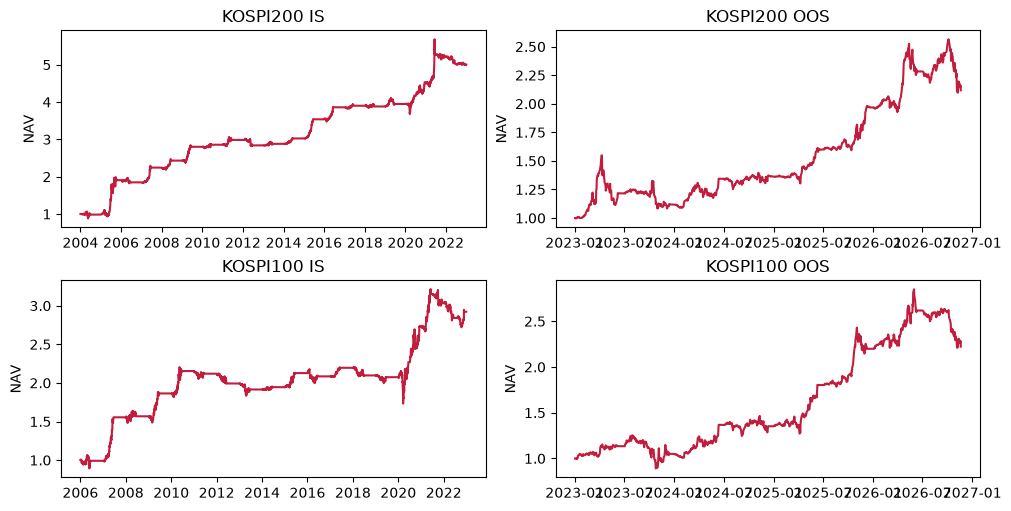

In [5]:
show(perf[perf.n_splits.eq(4)][['index_id','phase','period_start','period_end','review_events','total_return','cagr','volatility','sharpe','mdd','mean_exposure']])
fig,axes=plt.subplots(2,2,figsize=(10,5),layout='constrained')
for i,idx in enumerate(IDS):
    for j,phase in enumerate(['IS','OOS']):
        d=stand.query('index_id==@idx and phase==@phase')
        axes[i,j].plot(d.date,d.equity/1e10,color='#c31d3e')
        axes[i,j].set_title(f'{idx} {phase}'); axes[i,j].set_ylabel('NAV')
plt.show()


## 5. 두 전략을 함께 집행한 200억 원 계좌

단독 결과를 평균하지 않고 공표 탈락 청산까지 포함한 주문 원장을 다시 계산했습니다. IS 통합은 두 지수를 함께 운용할 수 있는 2006년부터입니다. OOS에서는 200억 원으로 다시 시작합니다. 샤프 기본값은 전체 계좌 일별 수익률에서 CD 91일물 수익률을 뺀 뒤 연율화한 값입니다.


,phase,index_id,ending_equity_krw,total_return,cagr,volatility,sharpe,mdd,initial_fill_ratio
0,IS,KOSPI200,40747475415.164612,307.47%,8.62%,7.42%,0.811,-14.54%,93.41%
1,IS,KOSPI100,28854718420.017570,188.55%,6.44%,9.32%,0.441,-22.15%,99.20%
2,IS,COMBINED,69602193835.182190,248.01%,7.62%,7.28%,0.695,-14.97%,96.23%
3,OOS,KOSPI200,21175151610.858524,111.75%,21.32%,20.98%,0.896,-30.08%,95.87%
4,OOS,KOSPI100,22222415460.250988,122.22%,22.84%,25.39%,0.829,-28.94%,96.76%
5,OOS,COMBINED,43397567071.109512,116.99%,22.08%,19.98%,0.963,-26.43%,96.32%


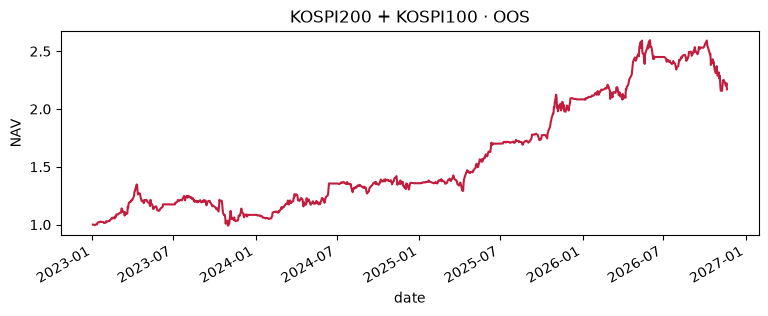

,index_id,phase,sessions,exposed_intervals,full_cd,holding_period_cd,exposure_weighted_cd
0,COMBINED,OOS,948,899,0.963,0.971,1.058
1,KOSPI100,OOS,948,844,0.829,0.844,0.904
2,KOSPI200,OOS,948,899,0.896,0.904,0.986


In [6]:
show(metrics[['phase','index_id','ending_equity_krw','total_return','cagr','volatility','sharpe','mdd','initial_fill_ratio']])
oos.equity.div(2e10).plot(title='KOSPI200 + KOSPI100 · OOS',ylabel='NAV',figsize=(9,3),color='#c31d3e')
plt.show()
display(pd.read_csv(OUT/'OOS_sharpe.csv')[['index_id','phase','sessions','exposed_intervals','full_cd','holding_period_cd','exposure_weighted_cd']].round(3))


보유일 기준은 직전 종가에 주식이 있으면 계좌 전체에 CD 이자를 적용합니다. 실제 투자 비중 기준은 직전 종가의 주식 비중만큼만 적용합니다. 두 계산 모두 현금일을 포함한 일별 계좌 수익률을 사용하므로 기준 변경이 최종 자산이나 최대낙폭을 바꾸지 않습니다.

### 회차 단위의 반복성과 실제 투입금액

각 체결분의 매수 원가에 매수 종가부터 실제 청산 종가까지의 CD 이자를 계산했습니다. 회차 초과수익률은 (비용 차감 순손익 − CD 이자) ÷ 매수 원가입니다. 두 지수가 같은 정기변경을 거래하므로 통합 결과도 7회입니다.

아래 승률·손익비는 **청산을 마친 7회**만 집계합니다. 2026년 12월은 진입 후 아직 청산 전인 8번째 회차입니다. 계좌 NAV에는 포함하지만 완료 회차 승률에는 넣지 않습니다.

In [7]:
ev=pd.read_csv(OUT/'OOS_events.csv')
display(ev.pivot(index='event',columns='index_id',values='excess_return').style.format('{:+.2%}'))
for idx,g in ev.groupby('index_id'):
    r=g.excess_return
    print(f'{idx}  평균 {r.mean():+.2%}  중앙값 {r.median():+.2%}  승률 {(r>0).mean():.1%}  손익비 {r[r>0].mean()/-r[r<0].mean():.2f}')


index_id,COMBINED,KOSPI100,KOSPI200
event,,,
2023-06,+23.58%,+16.84%,+31.16%
2023-12,-10.30%,-9.57%,-11.03%
2024-06,+31.71%,+38.01%,+25.66%
2024-12,-1.14%,-2.61%,+0.52%
2025-06,+35.64%,+44.77%,+25.72%
2025-12,+38.82%,+40.50%,+37.15%
2026-06,+36.79%,+43.24%,+30.66%


COMBINED  평균 +22.16%  중앙값 +31.71%  승률 71.4%  손익비 5.82
KOSPI100  평균 +24.45%  중앙값 +38.01%  승률 71.4%  손익비 6.02
KOSPI200  평균 +19.98%  중앙값 +25.72%  승률 85.7%  손익비 2.28


## 6. 보유 일정과 최근 포트폴리오

월별 주식 비중은 일별 종가의 주식 평가액 ÷ 계좌 순자산의 월평균입니다. 공표 탈락주의 청산이 반영된 월별 경로와 변경 직전 보유 종목을 아래에 표시합니다. 스냅샷의 종목 수와 순위도 기존 원장과 달라집니다.


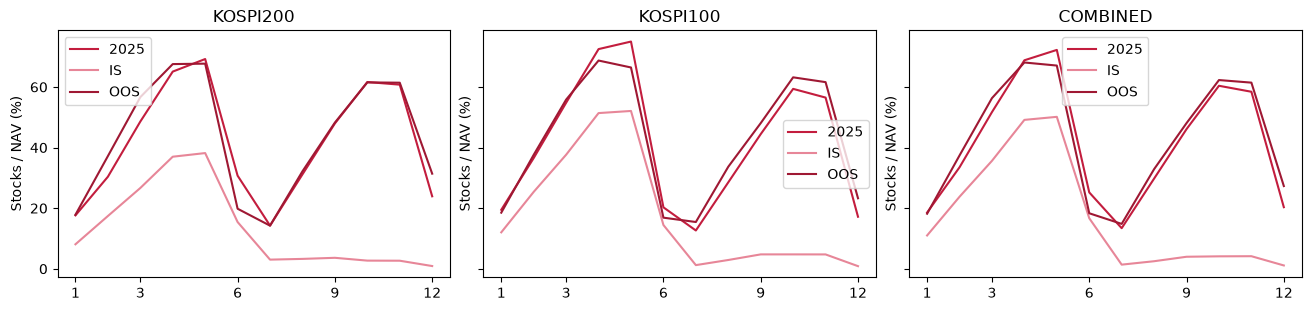

2025-12


,name,strategies,평가액(억원),잔여 원가 대비 수익률
0,이수페타시스,KOSPI200,40.8,+135.75%
1,현대오토에버,KOSPI200,31.9,+84.12%
2,효성중공업,KOSPI100,52.3,+74.24%
3,두산,KOSPI100,48.0,+60.19%
4,아세아,KOSPI200,12.2,+8.32%
5,파라다이스,KOSPI200,16.4,-5.44%
6,LG씨엔에스,KOSPI200,16.0,-7.52%


2026-06


,name,strategies,평가액(억원),잔여 원가 대비 수익률
7,현대오토에버,KOSPI100,55.8,+76.21%
8,DB하이텍,KOSPI200,42.1,+71.32%
9,에이피알,KOSPI100,27.6,+44.03%
10,달바글로벌,KOSPI200,32.6,+32.77%
11,키움증권,KOSPI100,27.8,-12.16%


In [8]:
profile=pd.read_csv(OUT/'monthly_exposure.csv')
fig,axes=plt.subplots(1,3,figsize=(13,3),sharey=True,layout='constrained')
for idx,ax in zip([*IDS,'COMBINED'],axes):
    d=profile[profile.index_id.eq(idx)]
    for label,color in [('2025','#c31d3e'),('IS','#e78698'),('OOS','#9f1833')]:
        g=d[d.period.eq(label)]
        if not g.empty: ax.plot(g.month,g.stock_share*100,label=label,color=color)
    ax.set_title(idx); ax.set_ylabel('Stocks / NAV (%)'); ax.set_xticks([1,3,6,9,12]); ax.legend()
plt.show()
snap=pd.read_csv(OUT/'snapshots.csv')
for event,g in snap.groupby('event'):
    print(event)
    display(g[['name','strategies','market_value_krw','gain']].assign(market_value_krw=g.market_value_krw/1e8).rename(columns={'market_value_krw':'평가액(억원)','gain':'잔여 원가 대비 수익률'}).style.format({'평가액(억원)':'{:.1f}','잔여 원가 대비 수익률':'{:+.2%}'}))


### 2026년 하반기 목표·주문·일별 보유 원장

새 FnGuide 구성종목 여부·유동주식비율과 KRX 시세로 7월 3일·8월 3일·9월 1일·10월 1일부터의 분할매수를 재계산했습니다. 신호는 각각 직전 거래일 정보로 산출합니다. 최신 구성종목 여부를 과거 예측의 정답으로 사용하지 않습니다.

사용자 지정 정보 정책에 따라 네 신호는 당시 GICS 분류를 사용했습니다. KRICS 공개 뒤에는 새 분류를 사용할 수 있으나 이미 끝난 신호를 소급 변경하거나 다섯 번째 매수를 만들지 않습니다.

KOSPI200은 11월 18일 공표 명단으로 11월 19일부터 탈락주 매도를 판단합니다. KOSPI100의 12월 변경 확정 명단은 11월 20일까지 확보하지 못해 미확정 상태로 유지합니다. 관리종목 상태의 9월 7일 이후 공백과 한화 계열 분할 종목의 심사기간 확인 공백은 남아 있습니다. 따라서 하반기는 자료 한계가 있는 연구 재구성입니다.

신규 파일의 과거 구성종목 여부 일부는 기존 당시 명단과 다릅니다. 예를 들어 2006년 3월 KOSPI200은 새 파일에 198개만 표시되어 과거 공식·기존 검증 명단을 일괄 덮어쓰지 않았습니다. 과거 확정 입력은 유지하고 하반기 자료를 연결했습니다. 유동비율 10% 경계 변화는 일성신약 2023년 네 신호에서 확인했으나 재선정 결과 최종 명단 변화는 없었습니다. 상세 대조는 historical_input_signal_audit.csv에 남겼습니다.

2026년 하반기 시가총액은 같은 날의 수정 전 종가와 상장주식수를 곱해 계산했습니다. 수정주가는 20거래일 추세, 수정 전 종가와 거래대금은 체결·평가에 사용했습니다. 상반기까지는 기존에 검증한 입력과 기업행위 처리 이력을 연결했습니다. KRX 자료는 시장 구분, 공표, 업종 및 기업행위 대조에 사용합니다.

## 7. KOSPI200 추세보정 엔진과 증권사 리포트의 동일 시점 비교

리포트에 **자료 기준일이 명시된 13건·정기변경 9회**를 본 비교로 삼습니다. 그날까지의 가격과 시총, 당시 구성 명단으로 추세보정 엔진을 다시 실행해 신규 정기편입을 예측했습니다. 정밀도는 예측 종목 중 실제 편입된 비율, 재현율은 실제 편입 중 포착한 비율입니다. 같은 회차의 여러 리포트가 중복 가중되지 않도록 회차 안에서 적중 수·예측 수·실제 편입 수를 각각 평균한 다음 회차를 합산했습니다.

매매 비교는 리포트마다 양쪽에 별도로 100억 원을 배정해 공개 다음 거래일 종가부터 명단 안에서 균등 목표로 매수합니다. 최대 10거래일 동안 매수하고, 지수 공표 명단에서 빠진 종목은 다음 거래일 종가부터, 편입된 종목은 패시브 매매일 종가부터 청산합니다. 하루 종목별 한도는 직전 20거래일 평균 및 당일 거래대금 중 작은 금액의 10%, 편도 비용은 25bp입니다. **회차 수익률**은 리포트별 순손익을 예산 100억 원으로 나눈 뒤 같은 회차 안에서 평균한 값입니다. 첫 표의 **회차 승률**은 수익이 양수인 정기변경 회차의 비율이고, **회차 손익비**는 이익 회차 평균 ÷ 손실 회차 평균의 절댓값입니다. 아래 두 번째 표에서는 **종목×정기변경 회차**를 한 건으로 세어 승률과 손익비를 다시 계산합니다. 같은 종목이 같은 회차의 여러 리포트에 반복되면 체결 원가 대비 수익률을 먼저 평균합니다. 편입 예측 실패 종목과 비용·거래대금 제한을 모두 포함하며, 49건·43건을 독립적인 정기변경으로 해석하지 않습니다. 무위험수익 차감 전입니다. 이 비교는 명단을 평가하므로 80·60·40·20일의 네 차수 계좌와 진입일이 다릅니다.

In [9]:
comp=OUT/'broker_comparison'
summary=pd.read_csv(comp/'summary.csv')
pairs=pd.read_csv(comp/'pairs.csv')
def broker_table(design):
    cols=['who','reports','reviews','precision','recall','win','payoff','mean_net']
    tab=summary.loc[summary.design.eq(design),cols].copy()
    tab.who=tab.who.map({'engine':'추세보정 엔진','broker':'증권사'})
    tab.columns=['구분','리포트','회차','정밀도','재현율','회차 승률','손익비','회차 평균 순수익률']
    display(tab.set_index('구분').style.format({'정밀도':'{:.1%}','재현율':'{:.1%}','회차 승률':'{:.1%}','손익비':'{:.2f}배','회차 평균 순수익률':'{:+.2%}'}))
broker_table('declared_inputs')
stock=pd.read_csv(comp/'stock_trade_summary.csv')
stock=stock[stock.unit.eq('stock_event') & stock.design.eq('declared_inputs')].copy()
stock.who=stock.who.map({'engine':'추세보정 엔진','broker':'증권사'})
stock=stock.rename(columns={'who':'구분','observations':'종목×회차','wins':'이익 건수','win_rate':'종목 승률','payoff':'종목 손익비','mean_return':'종목 평균 체결액 대비 수익률'})
display(stock[['구분','종목×회차','이익 건수','종목 승률','종목 손익비','종목 평균 체결액 대비 수익률']].set_index('구분').style.format({'종목 승률':'{:.1%}','종목 손익비':'{:.2f}배','종목 평균 체결액 대비 수익률':'{:+.2%}'}))
primary=pairs[pairs.design.eq('declared_inputs')]
assert not primary.net.isna().any() and primary.groupby('report_id').who.nunique().eq(2).all()
rounds=primary.groupby(['event','who']).net.mean().unstack().rename(columns={'engine':'추세보정 엔진','broker':'증권사'})
display(rounds.style.format('{:+.2%}'))

,리포트,회차,정밀도,재현율,회차 승률,손익비,회차 평균 순수익률
구분,,,,,,,
증권사,13,9,90.9%,68.6%,44.4%,1.53배,+0.83%
추세보정 엔진,13,9,87.5%,82.4%,55.6%,3.19배,+6.46%


,종목×회차,이익 건수,종목 승률,종목 손익비,종목 평균 체결액 대비 수익률
구분,,,,,
증권사,43,26,60.5%,1.05배,+3.83%
추세보정 엔진,49,31,63.3%,1.84배,+9.53%


who,증권사,추세보정 엔진
event,,
2020-06,+25.45%,+24.25%
2020-12,+11.49%,+9.00%
2021-12,+1.14%,+1.14%
2022-12,-0.78%,-0.83%
2023-06,-1.01%,-0.81%
2023-12,-3.82%,-4.56%
2024-12,+3.12%,+7.01%
2025-12,-5.36%,+36.15%
2026-06,-22.77%,-13.26%


**회차 기준:** 엔진은 9회 중 5회, 증권사는 4회에서 이익이 났습니다. 손익비는 각각 3.19배와 1.53배입니다. **종목×회차 기준:** 엔진은 49건 중 31건이 이익으로 승률 63.3%, 손익비 1.84배입니다. 증권사는 43건 중 26건이 이익으로 승률 60.5%, 손익비 1.05배입니다. 반복 리포트를 각각 한 번씩 세면 엔진 70건의 승률 58.6%·손익비 2.18배, 증권사 55건의 54.5%·1.62배로 달라집니다. 장표는 같은 종목·같은 회차를 중복 계산하지 않는 종목×회차 기준을 사용합니다.

종목 수익률의 분모는 **실제 체결 매수액과 비용**입니다. 회차 평균 순수익률의 분모는 각 리포트의 **100억 원 계좌 예산**이므로 두 평균 수익률을 직접 비교하지 않습니다. 증권사는 정밀도가 높고 엔진은 재현율이 높습니다. 같은 날 입력을 사용한 13건에서는 추세 보정 후에도 최종 예측 명단이 종전 규정 엔진과 모두 같았습니다. 이 표만으로 추세 보정 자체가 적중률을 높였다고 판단하기 어렵습니다.

**보조 비교.** KOSPI200 확보 리포트 47건 중 공개일에 엔진을 재실행해 비교 가능한 범위는 31건·13회입니다. 자료 기준일까지 일치한 위 표본이 여기에 포함됩니다. 공개일에는 리포트 작성자가 이미 사용한 기준일 이후 정보가 엔진에 들어갈 수 있습니다.

In [10]:
broker_table('release_day')
coverage=pd.read_csv(SRC/'rule_coverage.csv').query('index_id in @IDS')
display(coverage.groupby(['index_id','status']).size().unstack(fill_value=0))

,리포트,회차,정밀도,재현율,회차 승률,손익비,회차 평균 순수익률
구분,,,,,,,
증권사,31,13,92.8%,70.8%,53.8%,1.68배,+2.11%
추세보정 엔진,31,13,88.4%,86.3%,53.8%,3.64배,+6.78%


status,dated_rule_partial,dated_rule_research,historical_research_proxy
index_id,,,
KOSPI100,0,41,65
KOSPI200,12,52,48


## 재현 안내

이 제출본은 동봉한 집행 원장과 검증 데이터를 읽어 전략 설명·성과 표·그래프를 다시 계산합니다. 전체 역사적 원장을 처음부터 생성하는 엔진은 별도의 원본 프로젝트 환경을 사용합니다. 이 폴더의 `04_results/`와 `01_data/`는 노트북 재실행 및 자료 감사에 필요한 범위로 복사했습니다. `포트폴리오_신호일_실제보유.csv`는 신호일 종가의 모의 체결 보유 내역이며 실제 증권계좌 체결 기록은 아닙니다.


## 전체 거래일 모의 포트폴리오

**2006-01-02~2026-11-20**의 매 거래일 종가 보유 원장입니다. 비중은 통합계좌 자산 대비 평가액이며 현금(CASH)을 포함하면 매일 합계가 1입니다. 같은 종목을 두 전략이 보유하면 전략별 행을 유지합니다. 주식이 없는 날도 현금 행을 저장합니다.

포트폴리오_일별_실제보유.csv가 전체 보유 DF이며 포트폴리오_신호일_실제보유.csv는 신호일만 추린 보조 자료입니다. 파일명의 실제보유는 모의 체결 후 남아 있는 포지션을 의미하며 실계좌 기록이 아닙니다. IS·OOS는 별도 초기화한 계좌입니다.

In [11]:
positions=pd.read_csv(root/'포트폴리오_일별_실제보유.csv', parse_dates=['date'], dtype={'종목코드':str})
stock_positions=positions.loc[positions['자산구분'].eq('주식')].copy()
print('전체 기간:', positions.date.min(), '~', positions.date.max(), '거래일:', positions.date.nunique())
latest_stock_date=stock_positions.date.max()
display(positions.loc[positions.date.eq(latest_stock_date), ['date','종목명','종목코드','비중','전략신호','자산구분']].style.format({'비중':'{:.2%}'}))
display(positions.loc[positions.date.eq(positions.date.max()), ['date','종목명','종목코드','비중','전략신호','자산구분']].style.format({'비중':'{:.2%}'}))
assert positions.groupby('date')['비중'].sum().sub(1).abs().max()<1e-9


전체 기간: 2006-01-02 00:00:00 ~ 2026-11-20 00:00:00 거래일: 5150


,date,종목명,종목코드,비중,전략신호,자산구분
46738,2026-11-20 00:00:00,가온전선,A000500,0.87%,KOSPI100 정기 신규편입 예측,주식
46739,2026-11-20 00:00:00,신세계,A004170,0.47%,KOSPI100 정기 신규편입 예측,주식
46740,2026-11-20 00:00:00,LS,A006260,4.15%,KOSPI100 정기 신규편입 예측,주식
46741,2026-11-20 00:00:00,이수페타시스,A007660,2.71%,KOSPI100 정기 신규편입 예측,주식
46742,2026-11-20 00:00:00,대우건설,A047040,2.02%,KOSPI100 정기 신규편입 예측,주식
46743,2026-11-20 00:00:00,산일전기,A062040,0.54%,KOSPI100 정기 신규편입 예측,주식
46744,2026-11-20 00:00:00,LG씨엔에스,A064400,1.36%,KOSPI100 정기 신규편입 예측,주식
46745,2026-11-20 00:00:00,HD건설기계,A267270,1.81%,KOSPI100 정기 신규편입 예측,주식
46746,2026-11-20 00:00:00,가온전선,A000500,3.47%,KOSPI200 정기 신규편입 예측,주식
46747,2026-11-20 00:00:00,효성,A004800,0.56%,KOSPI200 정기 신규편입 예측,주식


,date,종목명,종목코드,비중,전략신호,자산구분
46738,2026-11-20 00:00:00,가온전선,A000500,0.87%,KOSPI100 정기 신규편입 예측,주식
46739,2026-11-20 00:00:00,신세계,A004170,0.47%,KOSPI100 정기 신규편입 예측,주식
46740,2026-11-20 00:00:00,LS,A006260,4.15%,KOSPI100 정기 신규편입 예측,주식
46741,2026-11-20 00:00:00,이수페타시스,A007660,2.71%,KOSPI100 정기 신규편입 예측,주식
46742,2026-11-20 00:00:00,대우건설,A047040,2.02%,KOSPI100 정기 신규편입 예측,주식
46743,2026-11-20 00:00:00,산일전기,A062040,0.54%,KOSPI100 정기 신규편입 예측,주식
46744,2026-11-20 00:00:00,LG씨엔에스,A064400,1.36%,KOSPI100 정기 신규편입 예측,주식
46745,2026-11-20 00:00:00,HD건설기계,A267270,1.81%,KOSPI100 정기 신규편입 예측,주식
46746,2026-11-20 00:00:00,가온전선,A000500,3.47%,KOSPI200 정기 신규편입 예측,주식
46747,2026-11-20 00:00:00,효성,A004800,0.56%,KOSPI200 정기 신규편입 예측,주식


## 갱신 자료와 미청산 회차 점검

마지막 날 KOSPI100 100개, KOSPI200 201개가 관측됩니다. 하반기 손익에는 열린 포지션 평가손익이 들어갑니다. 차수별 목표 수, 체결금액과 잔여 현금은 아래 자료에서 확인합니다.

In [12]:
import json
display(pd.DataFrame(json.loads((OUT/'input_audit.json').read_text(encoding='utf-8')))[['field','first','last','codes','latest_members']])
display(pd.read_csv(OUT/'H2_contribution.csv')[['index_id','H2_pnl','H2_account_return','H2_return_per_fixed_budget','fill_ratio','distinct_codes']].style.format({'H2_account_return':'{:+.2%}','H2_return_per_fixed_budget':'{:+.2%}','fill_ratio':'{:.2%}'}))
display(pd.read_csv(OUT/'forecast_audit.csv')[['index_id','lead','information_date','selected','management_source_date']])
print('왕복 거래비용 민감도 (동일 종료일)')
show(pd.read_csv(OUT/'cost_sensitivity_oos.csv')[['index_id','roundtrip_bp','total_return','cagr','sharpe','mdd']])

display(pd.DataFrame(json.loads((OUT/'market_input_audit.json').read_text(encoding='utf-8')))[['field','csv','last','last_valid']])

,field,first,last,codes,latest_members
0,float_ratio,2000-01-04,2026-11-20,4013,NaN
1,KOSPI100,2000-01-04,2026-11-20,4013,100.0
2,KOSPI200,2000-01-04,2026-11-20,4013,201.0


,index_id,H2_pnl,H2_account_return,H2_return_per_fixed_budget,fill_ratio,distinct_codes
0,COMBINED,-5607549128.323364,-11.44%,-28.04%,100.00%,15
1,KOSPI100,-3955864190.792511,-15.11%,-39.56%,100.00%,8
2,KOSPI200,-1651684937.530850,-7.24%,-16.52%,100.00%,8


,index_id,lead,information_date,selected,management_source_date
0,KOSPI200,80,2026-07-02,7,2026-07-02
1,KOSPI100,80,2026-07-02,5,2026-07-02
2,KOSPI200,60,2026-07-31,5,2026-07-31
3,KOSPI100,60,2026-07-31,2,2026-07-31
4,KOSPI200,40,2026-08-31,6,2026-08-31
5,KOSPI100,40,2026-08-31,4,2026-08-31
6,KOSPI200,20,2026-09-30,4,2026-09-07
7,KOSPI100,20,2026-09-30,3,2026-09-07


왕복 거래비용 민감도 (동일 종료일)


,index_id,roundtrip_bp,total_return,cagr,sharpe,mdd
0,KOSPI200,40,112.57%,21.44%,0.902,-30.02%
1,KOSPI100,40,123.03%,22.95%,0.834,-28.90%
2,COMBINED,40,117.78%,22.20%,0.969,-26.36%
3,KOSPI200,50,111.78%,21.32%,0.896,-30.08%
4,KOSPI100,50,122.24%,22.84%,0.829,-28.94%
5,COMBINED,50,116.99%,22.08%,0.963,-26.43%
6,KOSPI200,60,110.99%,21.21%,0.891,-30.14%
7,KOSPI100,60,121.45%,22.73%,0.825,-28.98%
8,COMBINED,60,116.20%,21.97%,0.957,-26.49%


,field,csv,last,last_valid
0,close,코스피_코스닥_종가_1120.csv,2026-11-20,2637
1,adjusted,코스피코스닥_수정주가_1120.csv,2026-11-20,2637
2,turnover,코스피_코스닥_거래대금_1120.csv,2026-11-20,2637
3,shares,코스피_코스닥_상장주식수_1120.csv,2026-11-20,2637


## 강건성 검증 · OOS Fama–French 3팩터 알파

**2023년 1월 2일~2026년 11월 20일, 948거래일**의 비용 차감 후 통합계좌의 일일 NAV 수익률을 사용했습니다. 두 전략은 동일 종목·동일 거래일의 거래대금 한도를 공유합니다. 현금 보유일도 포함했습니다.

$R_{p,t}-R_{f,t}=\alpha+\beta_M (R_{m,t}-R_{f,t})+\beta_S SMB_t+\beta_H HML_t+\epsilon_t$

시장 팩터는 시가총액 가중 국내 주식 초과수익률이고, 규모(SMB)와 가치(HML)는 FnGuide 팩터 지수의 일간 변화율 대용치입니다. 무위험수익률은 CD91을 수익률 관측 기간에 맞게 환산해 사용했습니다.

일별 초과수익률을 종속변수로 하는 **일반 최소제곱법(OLS)**을 적용했습니다. 표준오차와 95% 신뢰구간은 일반 OLS 기준이며, p값은 각 계수가 0이라는 귀무가설에 대한 양측 t검정 결과입니다. 알파·알파 표준오차·알파 신뢰구간은 일별 절편 관련 값에 252를 곱해 연율 단위로 표시합니다. MKT·SMB·HML 계수는 팩터 민감도입니다. 표에서 계수·표준오차·신뢰구간은 소수로 표시합니다.

In [13]:
# 회귀식과 계수 추정 코드. 팩터 원자료를 별도로 준비하면 재추정한다.
if (OUT/'oos_ff3_factor_inputs.csv').exists():
    import statsmodels.api as sm
    
    factors = pd.read_csv(OUT/'oos_ff3_factor_inputs.csv', parse_dates=['date']).set_index('date')
    sample = oos[['return_daily']].join(factors, how='inner').sort_index()
    assert len(sample) == 948 and sample.notna().all().all()
    x = sm.add_constant(sample[['MKT_RF', 'SMB', 'HML']], has_constant='add')
    fit = sm.OLS(sample['return_daily'] - sample['RF'], x, missing='raise').fit()
    ci = fit.conf_int()
    table = pd.DataFrame({'계수': fit.params, '표준오차': fit.bse,
                          't값': fit.tvalues, 'p값': fit.pvalues,
                          '95% 하한': ci[0], '95% 상한': ci[1]})
    estimate_columns = ['계수', '표준오차', '95% 하한', '95% 상한']
    table.loc['const', estimate_columns] *= 252
    table = table.rename(index={'const': '알파 (연율)', 'MKT_RF': 'MKT (시장 초과수익률)',
                               'SMB': 'SMB (규모)', 'HML': 'HML (가치)'})
    
else:
    table = pd.read_csv(OUT/'oos_ff3_coefficients.csv', index_col=0)

estimate_columns = ['계수', '표준오차', '95% 하한', '95% 상한']

def format_estimate(value):
    return f'{value:+.4f}'

style = table.style.format({col: format_estimate for col in estimate_columns} |
                           {'t값': '{:.3f}', 'p값': lambda p: '<0.0001' if p < .0001 else f'{p:.4f}'})
display(style)


,계수,표준오차,t값,p값,95% 하한,95% 상한
알파 (연율),+0.1555,+0.0880,1.767,0.0776,-0.0172,+0.3282
MKT (시장 초과수익률),+0.3072,+0.0247,12.451,<0.0001,+0.2588,+0.3557
SMB (규모),+0.0441,+0.0409,1.077,0.2817,-0.0362,+0.1244
HML (가치),-0.0839,+0.0352,-2.386,0.0173,-0.1529,-0.0149


### 회귀 결과 해석

OOS 통합계좌의 연율 알파는 **+0.1555**이며, 양측 **p=0.0776**, 95% 신뢰구간은 **−0.0172~+0.3282**입니다. 5% 기준에서는 알파가 0과 다르다는 통계적 근거가 부족합니다.

시장 초과수익률(MKT) 계수 **+0.3072**는 다른 팩터가 같을 때 시장 초과수익률이 1%p 높은 날 계좌 초과수익률이 평균적으로 약 0.31%p 높게 관측됐다는 뜻입니다. 이 표본에서 시장과 가치(HML) 계수는 5% 기준으로 유의했고, 규모(SMB) 계수는 유의하지 않았습니다. 회귀의 결정계수는 **28.13%**입니다.

## 참고문헌과 데이터 출처

### 논문과 계산 방법

- Greenwood, R. & Sammon, M. (2025). [The Disappearing Index Effect](https://doi.org/10.1111/jofi.13410). *The Journal of Finance*. 미국 S&P 500의 편입 효과가 약해진 연구 배경에 사용했습니다.
- Franz, F.-C. (2020). [Forecasting index changes in the German DAX family](https://doi.org/10.1057/s41260-020-00153-6). *Journal of Asset Management*, 21, 135–153. 공개 시장 자료와 지수 방법론으로 순위를 예측하는 접근을 참고했습니다. 추세 반영 계수와 로그 한도는 국내 IS에서 선택했습니다.
- Fama, E. F. & French, K. R. (1993). [Common risk factors in the returns on stocks and bonds](https://doi.org/10.1016/0304-405X%2893%2990023-5). *Journal of Financial Economics*, 33(1), 3–56. 시장·규모·가치 조정 후 초과수익을 평가하는 회귀식의 근거입니다.

### 국내 규정·시장·검증 자료

| 사용처 | 원자료 | 제출본 재현 경로 |
|---|---|---|
| 편입 심사, 산업군, 공표와 효력일 | KRX KOSPI200 방법론 §6, KOSPI100·50 방법론 §2, 과거 개정본, 정기변경 공지·당시 구성명단, 산업분류 변경 공지(2026-09-28), KRICS 조회(2026-11-06), 시장구분·상장 및 기업행위 자료 | [방법론 PDF](../지수_방법론/) · [역사 적용 범위](../04_results/common_index_engine_20261119/rule_coverage.csv) · [공표 판정 원장](../04_results/kospi_pair_optimized_trend_20261124/announcement_decisions.csv) |
| 예측, 주문, 시가평가 | FnGuide 일별 수정 전 종가·수정주가·거래대금·시가총액·상장주식수·유동주식비율과 KOSPI200·KOSPI100 구성종목 여부. 2026년 하반기 시총은 같은 날 수정 전 종가×상장주식수로 산출 | [시세 원자료 대조](../04_results/kospi_pair_optimized_trend_20261124/market_input_audit.json) · [과거 입력 대조](../04_results/kospi_pair_optimized_trend_20261124/historical_input_signal_audit.csv) |
| 추종 ETF 순자산과 가격지수 | KRX ETF 일별매매정보의 순자산·기초지수명, FnGuide KOSPI200 가격지수. KOSPI200 가격·총수익 지수 추종 상품 합산, 레버리지·인버스 등 제외 | [연도별 ETF 순자산](../04_results/presentation_v4_20261118/etf_aum_yearly.csv) |
| 정기변경 전후 수급 | 미래에셋자산운용 TIGER200 공개 바스켓 신규 관측 19종목·3회, 외국인·기관·개인의 종목별 일간 순매수대금, 관측 시작 직전 시총 | [회차별 수급](../04_results/kospi_pair_optimized_trend_20261124/flow_t40_event_paths.csv) · [집계 규칙](../04_results/kospi_pair_optimized_trend_20261124/flow_t40_protocol.json) |
| 증권사 동일 시점 비교 | 삼성증권·메리츠증권·미래에셋증권·키움증권·유진투자증권 KOSPI200 정기변경 전망 원문 | [리포트별 기준일과 결과](../04_results/kospi_pair_optimized_trend_20261124/broker_comparison/pairs.csv) · 본 비교는 아래 13건 |
| 통합 OOS 3팩터 회귀 | 비용 차감 후 통합 NAV, FnGuide 팩터.csv의 Size & Book Value(2×3) SMB·HML, CD91(CD_91.csv 및 기존 CD91_일별.csv), 전일 시총 가중 국내 주식 수익률(2026-09-08 이후 FnGuide 시세로 연장) | [OOS 일별 원장](../04_results/kospi_pair_optimized_trend_20261124/OOS_daily.parquet) · [회귀 입력 RF·시장·규모·가치](../04_results/kospi_pair_optimized_trend_20261124/oos_ff3_factor_inputs.csv) · [시장 팩터 연장분](../04_results/kospi_pair_optimized_trend_20261124/market_factor_extension.csv) |

#### 증권사 동일 시점 비교에 사용한 13건

| 증권사 | 발행일 | 자료 기준일 | 정기변경 회차 | 원문 식별자 |
|---|---|---|---|---|
| 삼성증권 | 2020-04-10 | 2020-04-10 | 2020-06 | SAMSUNG_20200410_K200 |
| 유진투자증권 | 2020-04-14 | 2020-04-13 | 2020-06 | EUGENE_20200414_K200 |
| 삼성증권 | 2020-09-09 | 2020-09-08 | 2020-12 | SAMSUNG_20200909_K200 |
| 삼성증권 | 2021-11-04 | 2021-10-29 | 2021-12 | SAMSUNG_20211104_K200 |
| 삼성증권 | 2022-09-28 | 2022-09-27 | 2022-12 | SAMSUNG_20220928_K200 |
| 메리츠증권 | 2022-10-06 | 2022-10-04 | 2022-12 | MERITZ_20221006_K200 |
| 삼성증권 | 2023-03-02 | 2023-02-28 | 2023-06 | SAMSUNG_20230302_K200 |
| 메리츠증권 | 2023-03-29 | 2023-03-27 | 2023-06 | MERITZ_20230329_K200 |
| 삼성증권 | 2023-09-13 | 2023-09-12 | 2023-12 | SAMSUNG_20230913_K200 |
| 키움증권 | 2023-11-08 | 2023-11-07 | 2023-12 | KIWOOM_20231108_K200 |
| 삼성증권 | 2024-09-30 | 2024-09-26 | 2024-12 | SAMSUNG_20240930_K200 |
| 삼성증권 | 2025-09-26 | 2025-09-25 | 2025-12 | SAMSUNG_20250926_K200 |
| 미래에셋증권 | 2026-04-28 | 2026-04-27 | 2026-06 | MIRAE_20260428_K200 |